
 GENETIC ALGORITHM - ML OPTIMIZATION
1. Run Genetic Algorithm Optimization
2. Display Hyperparameter Search Space
3. Display Genetic Algorithm Steps
4. Exit

Enter your choice (1-4): 1
Enter Population Size (default 15): 15
Enter Number of Generations (default 8): 10

Starting Genetic Algorithm Optimization...

Generation 01/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 02/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 03/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 04/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 05/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 06/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 07/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 08/10 | Best Accuracy: 0.9238 | Parameters: [183, 19, 3]
Generation 09/10 | Best Accuracy: 0.9250 | Parameters: [183, 15, 3]
Generation 10/10 | Best Accuracy: 0.9250 | Parameters: [183, 15, 3]

=====

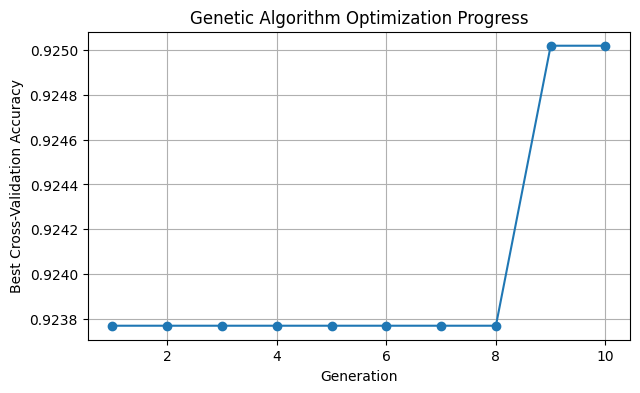


 GENETIC ALGORITHM - ML OPTIMIZATION
1. Run Genetic Algorithm Optimization
2. Display Hyperparameter Search Space
3. Display Genetic Algorithm Steps
4. Exit

Enter your choice (1-4): 2

========== HYPERPARAMETER SEARCH SPACE ==========
n_estimators  :  10 to 200
max_depth  :  2 to 20
min_samples_split  :  2 to 10

 GENETIC ALGORITHM - ML OPTIMIZATION
1. Run Genetic Algorithm Optimization
2. Display Hyperparameter Search Space
3. Display Genetic Algorithm Steps
4. Exit

Enter your choice (1-4): 3

========== GENETIC ALGORITHM STEPS ==========
1. Initialization: Generate a random population.
2. Fitness: Evaluate model accuracy.
3. Selection: Choose better individuals.
4. Crossover: Combine parent chromosomes.
5. Mutation: Randomly change some genes.
6. Elitism: Preserve the best individual.
7. Repeat: Continue for multiple generations.
8. Result: Return the best hyperparameters.

 GENETIC ALGORITHM - ML OPTIMIZATION
1. Run Genetic Algorithm Optimization
2. Display Hyperparameter Search 

In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


# ==========================================
# 1. DATASET CREATION
# ==========================================

X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=10,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ==========================================
# 2. HYPERPARAMETER SEARCH SPACE
# ==========================================

PARAM_BOUNDS = {
    'n_estimators': (10, 200),
    'max_depth': (2, 20),
    'min_samples_split': (2, 10)
}


# ==========================================
# 3. FITNESS FUNCTION
# ==========================================

def evaluate_fitness(individual):

    n_estimators, max_depth, min_samples_split = individual

    model = RandomForestClassifier(
        n_estimators=int(n_estimators),
        max_depth=int(max_depth),
        min_samples_split=int(min_samples_split),
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=3,
        scoring='accuracy'
    )

    return np.mean(scores)


# ==========================================
# 4. CREATE RANDOM INDIVIDUAL
# ==========================================

def create_individual():

    return [
        random.randint(*PARAM_BOUNDS['n_estimators']),
        random.randint(*PARAM_BOUNDS['max_depth']),
        random.randint(*PARAM_BOUNDS['min_samples_split'])
    ]


# ==========================================
# 5. SELECTION
# ==========================================

def selection(population, fitnesses, k=3):

    selected_indices = random.sample(
        range(len(population)), k
    )

    best_index = max(
        selected_indices,
        key=lambda i: fitnesses[i]
    )

    return population[best_index].copy()


# ==========================================
# 6. CROSSOVER
# ==========================================

def crossover(parent1, parent2, crossover_rate=0.8):

    if random.random() < crossover_rate:

        point = random.randint(1, len(parent1) - 1)

        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]

        return child1, child2

    return parent1.copy(), parent2.copy()


# ==========================================
# 7. MUTATION
# ==========================================

def mutate(individual, mutation_rate=0.2):

    keys = list(PARAM_BOUNDS.keys())

    for i in range(len(individual)):

        if random.random() < mutation_rate:

            bounds = PARAM_BOUNDS[keys[i]]

            individual[i] = random.randint(*bounds)

    return individual


# ==========================================
# 8. GENETIC ALGORITHM
# ==========================================

def genetic_algorithm(pop_size=15, generations=8):

    random.seed(42)
    np.random.seed(42)

    population = [
        create_individual()
        for _ in range(pop_size)
    ]

    best_overall_individual = None
    best_overall_fitness = -1

    history = []

    print("\nStarting Genetic Algorithm Optimization...\n")

    for gen in range(generations):

        # Evaluate fitness of every individual
        fitnesses = [
            evaluate_fitness(ind)
            for ind in population
        ]

        # Find best individual in current generation
        best_index = np.argmax(fitnesses)

        best_gen_fitness = fitnesses[best_index]
        best_gen_individual = population[best_index]

        # Update best overall solution
        if best_gen_fitness > best_overall_fitness:

            best_overall_fitness = best_gen_fitness
            best_overall_individual = best_gen_individual.copy()

        history.append(best_gen_fitness)

        print(
            f"Generation {gen + 1:02d}/{generations} | "
            f"Best Accuracy: {best_gen_fitness:.4f} | "
            f"Parameters: {best_gen_individual}"
        )

        # Create next generation
        new_population = []

        # Elitism: preserve the best individual
        new_population.append(
            best_gen_individual.copy()
        )

        while len(new_population) < pop_size:

            # Selection
            p1 = selection(population, fitnesses)
            p2 = selection(population, fitnesses)

            # Crossover
            c1, c2 = crossover(p1, p2)

            # Mutation
            new_population.append(
                mutate(c1)
            )

            if len(new_population) < pop_size:

                new_population.append(
                    mutate(c2)
                )

        population = new_population

    # ======================================
    # FINAL MODEL EVALUATION
    # ======================================

    n_estimators, max_depth, min_samples_split = (
        best_overall_individual
    )

    final_model = RandomForestClassifier(
        n_estimators=int(n_estimators),
        max_depth=int(max_depth),
        min_samples_split=int(min_samples_split),
        random_state=42,
        n_jobs=-1
    )

    final_model.fit(X_train, y_train)

    predictions = final_model.predict(X_test)

    test_accuracy = accuracy_score(
        y_test, predictions
    )

    print("\n========== OPTIMIZATION COMPLETED ==========")

    print("Best Cross-Validation Accuracy:",
          round(best_overall_fitness, 4))

    print("\nOptimal Hyperparameters:")

    print("Number of Trees (n_estimators):",
          best_overall_individual[0])

    print("Maximum Depth (max_depth):",
          best_overall_individual[1])

    print("Minimum Samples Split (min_samples_split):",
          best_overall_individual[2])

    print("\nFinal Test Accuracy:",
          round(test_accuracy, 4))

    # Plot optimization progress
    plt.figure(figsize=(7, 4))

    plt.plot(
        range(1, generations + 1),
        history,
        marker='o'
    )

    plt.xlabel("Generation")
    plt.ylabel("Best Cross-Validation Accuracy")
    plt.title("Genetic Algorithm Optimization Progress")
    plt.grid(True)
    plt.show()

    return best_overall_individual, best_overall_fitness, test_accuracy


# ==========================================
# 9. DISPLAY SEARCH SPACE
# ==========================================

def display_search_space():

    print("\n========== HYPERPARAMETER SEARCH SPACE ==========")

    for parameter, bounds in PARAM_BOUNDS.items():

        print(
            parameter,
            " : ",
            bounds[0],
            "to",
            bounds[1]
        )


# ==========================================
# 10. DISPLAY GA STEPS
# ==========================================

def display_ga_steps():

    print("\n========== GENETIC ALGORITHM STEPS ==========")

    print("1. Initialization: Generate a random population.")
    print("2. Fitness: Evaluate model accuracy.")
    print("3. Selection: Choose better individuals.")
    print("4. Crossover: Combine parent chromosomes.")
    print("5. Mutation: Randomly change some genes.")
    print("6. Elitism: Preserve the best individual.")
    print("7. Repeat: Continue for multiple generations.")
    print("8. Result: Return the best hyperparameters.")


# ==========================================
# 11. MAIN MENU
# ==========================================

while True:

    print("\n========================================")
    print(" GENETIC ALGORITHM - ML OPTIMIZATION")
    print("========================================")

    print("1. Run Genetic Algorithm Optimization")
    print("2. Display Hyperparameter Search Space")
    print("3. Display Genetic Algorithm Steps")
    print("4. Exit")

    choice = input("\nEnter your choice (1-4): ")

    if choice == "1":

        try:

            pop_size = int(
                input("Enter Population Size (default 15): ") or 15
            )

            generations = int(
                input("Enter Number of Generations (default 8): ") or 8
            )

            if pop_size < 3 or generations < 1:

                print("Population must be at least 3 and generations at least 1.")

            else:

                genetic_algorithm(
                    pop_size=pop_size,
                    generations=generations
                )

        except ValueError:

            print("Please enter valid integer values.")

    elif choice == "2":

        display_search_space()

    elif choice == "3":

        display_ga_steps()

    elif choice == "4":

        print("\nExiting Genetic Algorithm Program. Thank you!")
        break

    else:

        print("\nInvalid choice! Please select from 1 to 4.")
